# NIFTY 50 Financial Data Analysis and Forecasting

### Project 3 — End-to-End Financial Data Analytics Project

**Industry:** Finance / Stock Market Analytics  
**Dataset:** NIFTY 50 Historical Stock Market Data 
**Data Source:** https://www.kaggle.com/datasets/rohanrao/nifty50-stock-market-data 
**Period:** January 2000 – April 2021  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Statsmodels, Scikit-learn, PostgreSQL and Power BI  
**Forecasting model:** ARIMA (5, 1, 0)

**Workflow:** Data Extraction → Data Understanding → Data Cleaning → Feature Engineering → Statistical Analysis → EDA → Correlation Analysis → Forecasting → Model Evaluation → PostgreSQL → SQL Analysis → Power BI Dashboard → Business Insights

## 1. Setup and Imports

## 1. Import Libraries

Import the Python libraries required for data processing, visualization, time-series forecasting, evaluation and database connection.

In [1]:
%pip install pandas numpy matplotlib seaborn statsmodels scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import glob
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Dataset Extraction

Set the path to the downloaded ZIP file. The notebook extracts the archive into a folder and reads the individual stock CSV files. Update `ZIP_PATH` to match the location on your computer.

In [3]:
zip_path = r"C:\Users\ASUS\Desktop\Project 3 Financial Data Analysis and Forecasting (Power BITableau + Python)\NIFTY-50 Stock Market Data.zip"
extract_folder = "nifty50_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_folder)

print("Dataset extracted successfully!")
print("Number of files:", len(os.listdir(extract_folder)))

print(os.listdir(extract_folder)[:10])

Dataset extracted successfully!
Number of files: 52
['ADANIPORTS.csv', 'ASIANPAINT.csv', 'AXISBANK.csv', 'BAJAJ-AUTO.csv', 'BAJAJFINSV.csv', 'BAJFINANCE.csv', 'BHARTIARTL.csv', 'BPCL.csv', 'BRITANNIA.csv', 'CIPLA.csv']


## 3. Combine Individual Stock Files

Read each stock CSV file, add a `Stock` column based on its filename, and combine all stock datasets into one DataFrame. The combined file and metadata file are excluded to avoid duplicate data.

In [4]:
csv_files = glob.glob(os.path.join(extract_folder, "*.csv"))

stock_files = [
    file for file in csv_files
    if os.path.basename(file).lower()
    not in ["nifty50_all.csv", "stock_metadata.csv"]
]

dataframes = []

for file in stock_files:
    df = pd.read_csv(file)
    df["Stock"] = os.path.splitext(os.path.basename(file))[0]
    dataframes.append(df)

financial_df = pd.concat(dataframes, ignore_index=True)

print("Dataset shape:", financial_df.shape)
display(financial_df.head())

Dataset shape: (235192, 16)


,Date,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades,Deliverable Volume,%Deliverble,Stock
0,2007-11-27,MUNDRAPORT,EQ,440.0,770.0,1050.0,770.0,959.0,962.9,984.72,27294366,2687719053785000.0,NaN,9859619,0.3612,ADANIPORTS
1,2007-11-28,MUNDRAPORT,EQ,962.9,984.0,990.0,874.0,885.0,893.9,941.38,4581338,431276530165000.0,NaN,1453278,0.3172,ADANIPORTS
2,2007-11-29,MUNDRAPORT,EQ,893.9,909.0,914.75,841.0,887.0,884.2,888.09,5124121,455065846265000.0,NaN,1069678,0.2088,ADANIPORTS
3,2007-11-30,MUNDRAPORT,EQ,884.2,890.0,958.0,890.0,929.0,921.55,929.17,4609762,428325662830000.0,NaN,1260913,0.2735,ADANIPORTS
4,2007-12-03,MUNDRAPORT,EQ,921.55,939.75,995.0,922.0,980.0,969.3,965.65,2977470,287519974300000.0,NaN,816123,0.2741,ADANIPORTS


## 4. Understand the Dataset

Check the number of rows and columns, column names, data types, and statistical summary.

In [5]:
# Check column names
print("Columns:")
print(financial_df.columns.tolist())

# Check data types
print("\nData types:")
print(financial_df.dtypes)

# Check missing values
print("\nMissing values:")
display(financial_df.isnull().sum())

# Check duplicate records
print("\nDuplicate records:", financial_df.duplicated().sum())

# Statistical summary
display(financial_df.describe())

Columns:
['Date', 'Symbol', 'Series', 'Prev Close', 'Open', 'High', 'Low', 'Last', 'Close', 'VWAP', 'Volume', 'Turnover', 'Trades', 'Deliverable Volume', '%Deliverble', 'Stock']

Data types:
Date                  object
Symbol                object
Series                object
Prev Close            object
Open                  object
High                  object
Low                   object
Last                  object
Close                 object
VWAP                  object
Volume                object
Turnover              object
Trades                object
Deliverable Volume    object
%Deliverble           object
Stock                    str
dtype: object

Missing values:


Date                       0
Symbol                     0
Series                     0
Prev Close                 0
Open                       0
High                       0
Low                        0
Last                       0
Close                      0
VWAP                       0
Volume                     0
Turnover                   0
Trades                114848
Deliverable Volume     16077
%Deliverble            16077
Stock                      0
dtype: int64


Duplicate records: 0


,Date,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades,Deliverable Volume,%Deliverble,Stock
count,235192,235192,235192,235192.0,235192.0,235192.0,235192.0,235192.0,235192.0,235192.00,235192,235192.0,120344.0,219115.0,219115.0,235192
unique,5306,65,1,63729.0,44298.0,49036.0,51335.0,48570.0,63739.0,138831.00,220434,235184.0,79112.0,199963.0,9456.0,49
top,2010-11-04,ASIANPAINT,EQ,137.0,370.0,360.0,300.0,400.0,137.0,136.49,100,280000000.0,775.0,600.0,1.0,ASIANPAINT
freq,49,5306,235192,32.0,210.0,128.0,134.0,127.0,32.0,12.00,31,2.0,9.0,9.0,94.0,5306


In [6]:
# Convert Date column
financial_df["Date"] = pd.to_datetime(
    financial_df["Date"], errors="coerce"
)

# Numerical columns
numeric_columns = [
    "Prev Close",
    "Open",
    "High",
    "Low",
    "Last",
    "Close",
    "VWAP",
    "Volume",
    "Turnover",
    "Trades",
    "Deliverable Volume",
    "%Deliverble"
]

# Convert numerical columns
for col in numeric_columns:
    financial_df[col] = pd.to_numeric(
        financial_df[col], errors="coerce"
    )

# Remove rows with missing essential values
financial_df.dropna(
    subset=["Date", "Close", "Stock"],
    inplace=True
)

# Remove invalid closing prices
financial_df = financial_df[
    financial_df["Close"] > 0
]

# Sort the dataset
financial_df = financial_df.sort_values(
    by=["Stock", "Date"]
).reset_index(drop=True)

print("Data cleaning completed!")
print("Dataset shape:", financial_df.shape)

print("\nUpdated data types:")
print(financial_df.dtypes)

print("\nMissing values after cleaning:")
display(financial_df.isnull().sum())

Data cleaning completed!
Dataset shape: (235192, 16)

Updated data types:
Date                  datetime64[us]
Symbol                        object
Series                        object
Prev Close                   float64
Open                         float64
High                         float64
Low                          float64
Last                         float64
Close                        float64
VWAP                         float64
Volume                         int64
Turnover                     float64
Trades                       float64
Deliverable Volume           float64
%Deliverble                  float64
Stock                            str
dtype: object

Missing values after cleaning:


Date                       0
Symbol                     0
Series                     0
Prev Close                 0
Open                       0
High                       0
Low                        0
Last                       0
Close                      0
VWAP                       0
Volume                     0
Turnover                   0
Trades                114848
Deliverable Volume     16077
%Deliverble            16077
Stock                      0
dtype: int64

## 5. Data Cleaning

Convert the date and numeric columns to suitable data types. Remove duplicate rows and records without essential values (`Date`, `Close`, or `Stock`). Keep only positive closing prices. Missing values in optional columns such as `Trades` and `Deliverable Volume` are retained because they are not required for the main price analysis.

In [7]:
print("Missing values:")
display(financial_df.isnull().sum())

print("\nTotal missing values:")
print(financial_df.isnull().sum().sum())

print("\nMissing percentage:")
display(
    (financial_df.isnull().mean() * 100).round(2)
)

Missing values:


Date                       0
Symbol                     0
Series                     0
Prev Close                 0
Open                       0
High                       0
Low                        0
Last                       0
Close                      0
VWAP                       0
Volume                     0
Turnover                   0
Trades                114848
Deliverable Volume     16077
%Deliverble            16077
Stock                      0
dtype: int64


Total missing values:
147002

Missing percentage:


Date                   0.00
Symbol                 0.00
Series                 0.00
Prev Close             0.00
Open                   0.00
High                   0.00
Low                    0.00
Last                   0.00
Close                  0.00
VWAP                   0.00
Volume                 0.00
Turnover               0.00
Trades                48.83
Deliverable Volume     6.84
%Deliverble            6.84
Stock                  0.00
dtype: float64

## 6. Feature Engineering

Create year, month, daily percentage return, price change, 20-day rolling return volatility and year-month features. Calculations are grouped by stock so that one stock's price history is not mixed with another stock's history.

In [9]:
# Extract year and month
financial_df["Year"] = financial_df["Date"].dt.year
financial_df["Month"] = financial_df["Date"].dt.month

# Recalculate daily returns
financial_df["Daily_Return_%"] = (
    financial_df.groupby("Stock")["Close"].pct_change() * 100
)

# Recalculate price change
financial_df["Price_Change"] = (
    financial_df.groupby("Stock")["Close"].diff()
)

# Recalculate 20-day volatility
financial_df["Volatility_20D_%"] = (
    financial_df.groupby("Stock")["Daily_Return_%"]
    .transform(lambda x: x.rolling(20).std())
)

# Create Year-Month
financial_df["Year_Month"] = (
    financial_df["Date"].dt.to_period("M").astype(str)
)

# Display correctly ordered columns
display(
    financial_df[
        [
            "Date",
            "Stock",
            "Close",
            "Price_Change",
            "Daily_Return_%",
            "Volatility_20D_%",
            "Year",
            "Month",
            "Year_Month"
        ]
    ].head(25)
)

,Date,Stock,Close,Price_Change,Daily_Return_%,Volatility_20D_%,Year,Month,Year_Month
0,2007-11-27,ADANIPORTS,962.90,NaN,NaN,NaN,2007,11,2007-11
1,2007-11-28,ADANIPORTS,893.90,-69.00,-7.165853,NaN,2007,11,2007-11
2,2007-11-29,ADANIPORTS,884.20,-9.70,-1.085133,NaN,2007,11,2007-11
3,2007-11-30,ADANIPORTS,921.55,37.35,4.224157,NaN,2007,11,2007-11
4,2007-12-03,ADANIPORTS,969.30,47.75,5.181488,NaN,2007,12,2007-12
5,2007-12-04,ADANIPORTS,1041.45,72.15,7.443516,NaN,2007,12,2007-12
6,2007-12-05,ADANIPORTS,1082.45,41.00,3.936819,NaN,2007,12,2007-12
7,2007-12-06,ADANIPORTS,1081.30,-1.15,-0.106240,NaN,2007,12,2007-12
8,2007-12-07,ADANIPORTS,1102.40,21.10,1.951355,NaN,2007,12,2007-12
9,2007-12-10,ADANIPORTS,1075.40,-27.00,-2.449202,NaN,2007,12,2007-12


In [10]:
display(
    financial_df[
        ["Date", "Stock", "Close", "Price_Change",
         "Daily_Return_%", "Volatility_20D_%",
         "Year", "Month", "Year_Month"]
    ].head(25).to_string(index=False)
)

'      Date      Stock   Close  Price_Change  Daily_Return_%  Volatility_20D_%  Year  Month Year_Month\n2007-11-27 ADANIPORTS  962.90           NaN             NaN               NaN  2007     11    2007-11\n2007-11-28 ADANIPORTS  893.90        -69.00       -7.165853               NaN  2007     11    2007-11\n2007-11-29 ADANIPORTS  884.20         -9.70       -1.085133               NaN  2007     11    2007-11\n2007-11-30 ADANIPORTS  921.55         37.35        4.224157               NaN  2007     11    2007-11\n2007-12-03 ADANIPORTS  969.30         47.75        5.181488               NaN  2007     12    2007-12\n2007-12-04 ADANIPORTS 1041.45         72.15        7.443516               NaN  2007     12    2007-12\n2007-12-05 ADANIPORTS 1082.45         41.00        3.936819               NaN  2007     12    2007-12\n2007-12-06 ADANIPORTS 1081.30         -1.15       -0.106240               NaN  2007     12    2007-12\n2007-12-07 ADANIPORTS 1102.40         21.10        1.951355             

## 7. Stock-Wise Summary

Group the data by stock and calculate average, maximum and minimum closing prices, average trading volume, average daily return and return volatility.

In [11]:
stock_summary = (
    financial_df.groupby("Stock")
    .agg(
        Average_Close=("Close", "mean"),
        Maximum_Close=("Close", "max"),
        Minimum_Close=("Close", "min"),
        Average_Volume=("Volume", "mean"),
        Average_Return=("Daily_Return_%", "mean"),
        Return_Volatility=("Daily_Return_%", "std")
    )
    .reset_index()
)

display(stock_summary.head(10))

,Stock,Average_Close,Maximum_Close,Minimum_Close,Average_Volume,Average_Return,Return_Volatility
0,ADANIPORTS,344.201626,1307.45,108.00,2.954564e+06,0.052568,3.036997
1,ASIANPAINT,1247.410903,5213.10,210.75,5.096721e+05,0.080446,2.235503
2,AXISBANK,585.893931,2023.35,22.15,4.527938e+06,0.117750,3.054145
3,BAJAJ-AUTO,2190.412196,4237.45,301.90,4.114639e+05,0.082717,2.134453
4,BAJAJFINSV,2758.657451,11176.55,90.75,2.315312e+05,0.128234,2.525682
5,BAJFINANCE,1415.278023,11393.30,24.50,6.116085e+05,0.154723,3.065350
6,BHARTIARTL,379.800765,1125.65,20.75,5.341070e+06,0.085021,2.519128
7,BPCL,444.377629,1133.30,110.15,2.093650e+06,0.048808,2.949109
8,BRITANNIA,1688.492347,6900.15,336.35,1.220883e+05,0.059799,2.114622
9,CIPLA,540.421052,1465.25,160.10,1.550071e+06,0.032451,2.438257


In [12]:
display(stock_summary.to_string(index=False))

'     Stock  Average_Close  Maximum_Close  Minimum_Close  Average_Volume  Average_Return  Return_Volatility\nADANIPORTS     344.201626        1307.45         108.00    2.954564e+06        0.052568           3.036997\nASIANPAINT    1247.410903        5213.10         210.75    5.096721e+05        0.080446           2.235503\n  AXISBANK     585.893931        2023.35          22.15    4.527938e+06        0.117750           3.054145\nBAJAJ-AUTO    2190.412196        4237.45         301.90    4.114639e+05        0.082717           2.134453\nBAJAJFINSV    2758.657451       11176.55          90.75    2.315312e+05        0.128234           2.525682\nBAJFINANCE    1415.278023       11393.30          24.50    6.116085e+05        0.154723           3.065350\nBHARTIARTL     379.800765        1125.65          20.75    5.341070e+06        0.085021           2.519128\n      BPCL     444.377629        1133.30         110.15    2.093650e+06        0.048808           2.949109\n BRITANNIA    1688.492347  

## 8. Exploratory Data Analysis (EDA)

### 8.1 Top 10 Stocks by Average Closing Price

This chart compares average share prices. A higher share price does not automatically mean a better investment return because companies have different share-price levels.

In [13]:
top_10_stocks = stock_summary.sort_values(
    by="Average_Close",
    ascending=False
).head(10)

display(top_10_stocks.to_string(index=False))

'     Stock  Average_Close  Maximum_Close  Minimum_Close  Average_Volume  Average_Return  Return_Volatility\n NESTLEIND    7512.039647       18732.70        2489.35    5.449900e+04        0.078549           1.526100\n EICHERMOT    6751.063167       32861.95          17.70    9.628430e+04        0.137714           3.026231\n  SHREECEM    6565.809539       31748.75          24.10    2.507495e+04        0.151705           2.454658\n    MARUTI    2925.005094        9832.45         164.30    1.194661e+06        0.106520           2.172075\nBAJAJFINSV    2758.657451       11176.55          90.75    2.315312e+05        0.128234           2.525682\n      INFY    2581.885215       16855.90         526.45    2.622813e+06        0.011924           3.004204\nBAJAJ-AUTO    2190.412196        4237.45         301.90    4.114639e+05        0.082717           2.134453\nULTRACEMCO    2150.926570        6971.25         255.55    2.476179e+05        0.098792           2.095480\n   DRREDDY    1828.382689  

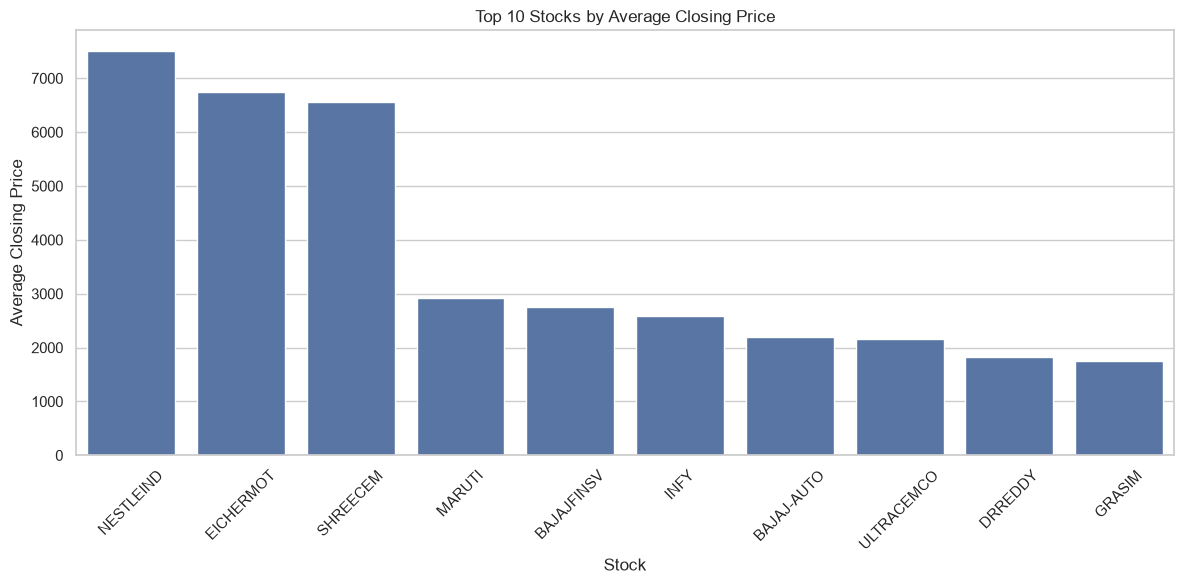

In [14]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_stocks,
    x="Stock",
    y="Average_Close"
)

plt.title("Top 10 Stocks by Average Closing Price")
plt.xlabel("Stock")
plt.ylabel("Average Closing Price")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 8.2 Top 10 Stocks by Average Daily Return

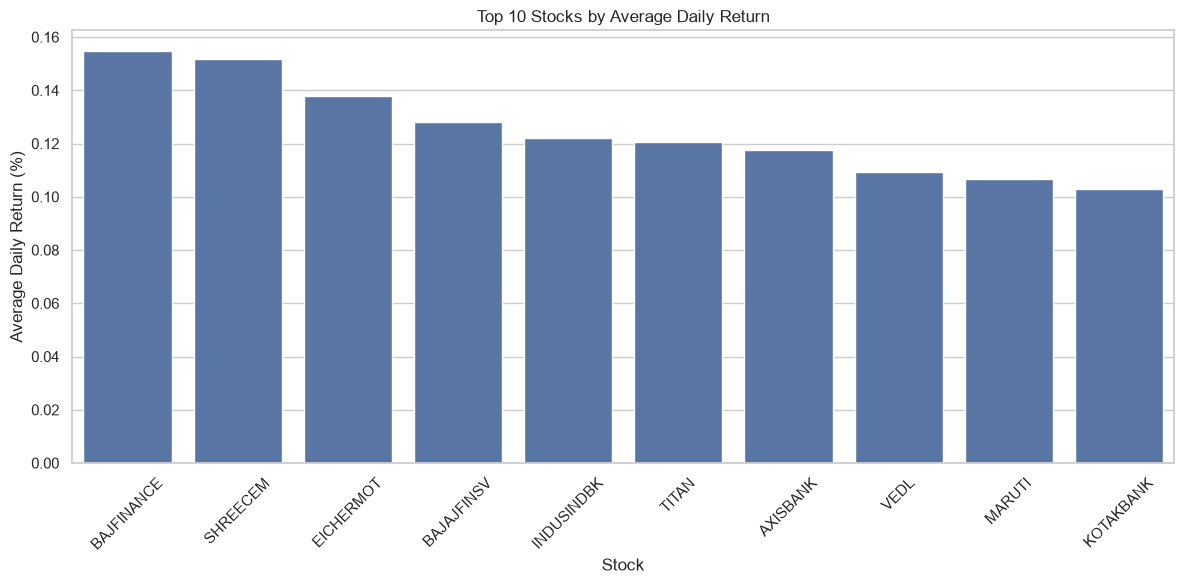

In [15]:
top_return_stocks = stock_summary.sort_values(
    by="Average_Return",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_return_stocks,
    x="Stock",
    y="Average_Return"
)

plt.title("Top 10 Stocks by Average Daily Return")
plt.xlabel("Stock")
plt.ylabel("Average Daily Return (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 8.3 Top 10 Stocks by Return Volatility

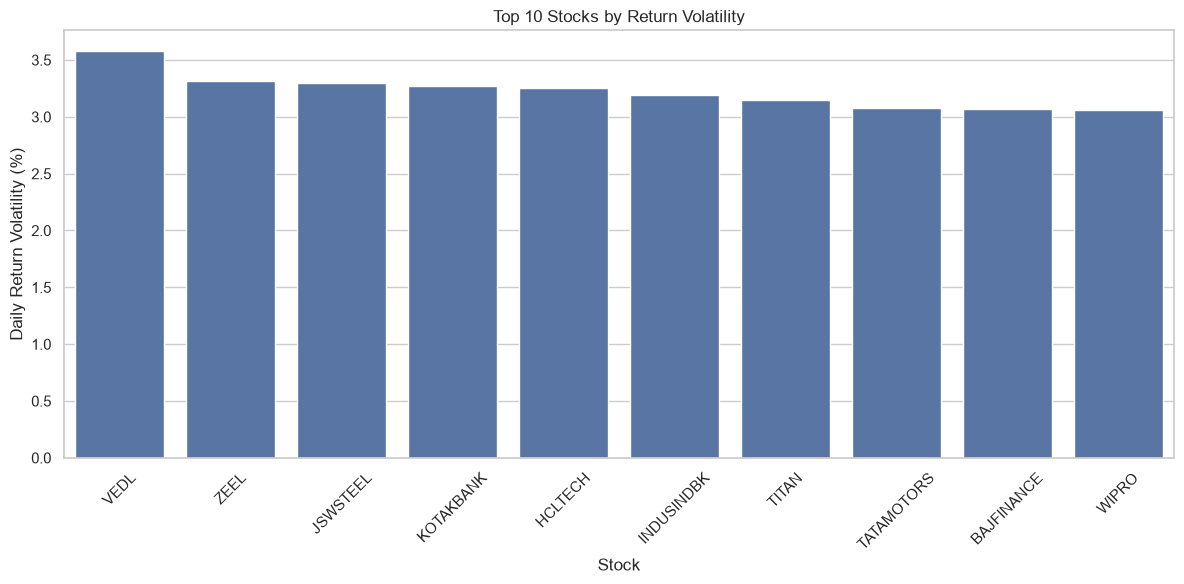

In [16]:
top_volatile_stocks = stock_summary.sort_values(
    by="Return_Volatility",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_volatile_stocks,
    x="Stock",
    y="Return_Volatility"
)

plt.title("Top 10 Stocks by Return Volatility")
plt.xlabel("Stock")
plt.ylabel("Daily Return Volatility (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 9. RELIANCE Stock Analysis

Filter the combined dataset for RELIANCE and analyze its closing price, trading volume, monthly performance, return distribution and volatility.

### 9.1 Historical Closing Price

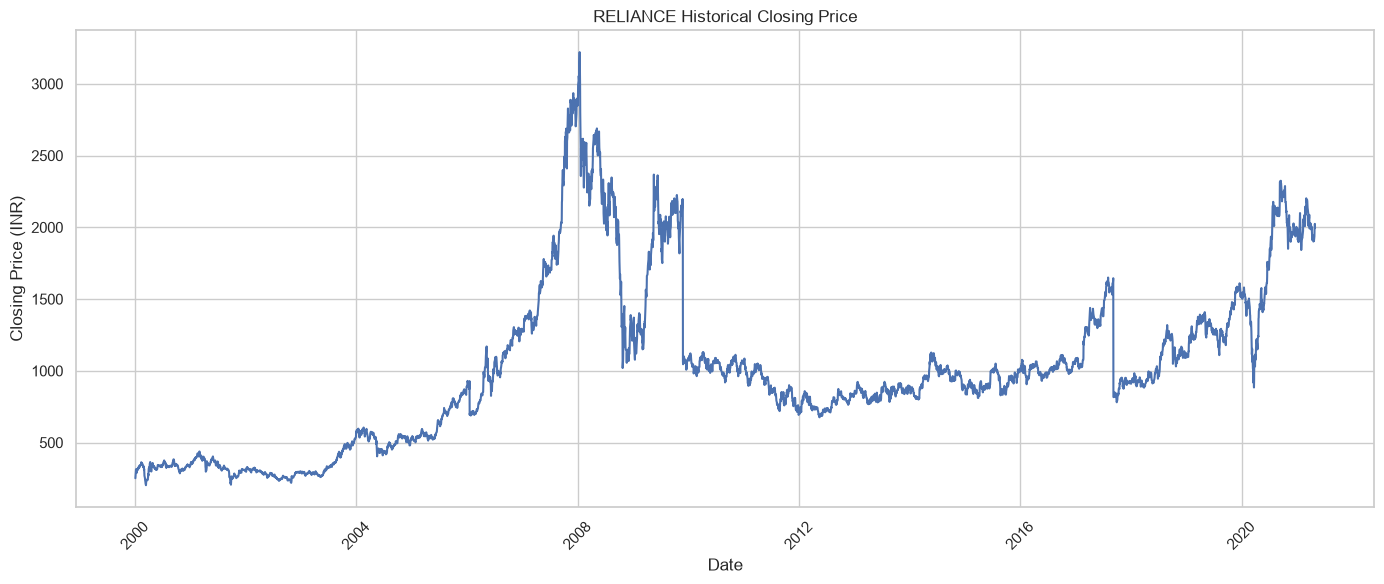

In [17]:
reliance_df = financial_df[
    financial_df["Stock"] == "RELIANCE"
].copy()

plt.figure(figsize=(14, 6))

plt.plot(
    reliance_df["Date"],
    reliance_df["Close"]
)

plt.title("RELIANCE Historical Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 9.2 Historical Trading Volume

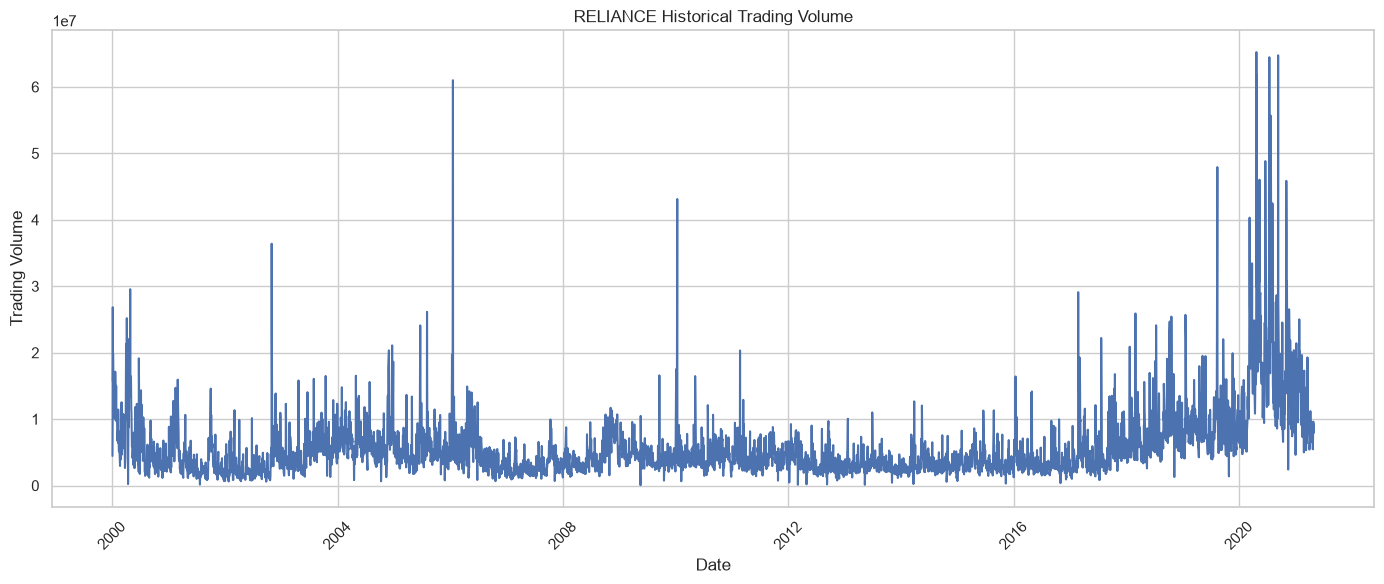

In [18]:
plt.figure(figsize=(14, 6))

plt.plot(
    reliance_df["Date"],
    reliance_df["Volume"]
)

plt.title("RELIANCE Historical Trading Volume")
plt.xlabel("Date")
plt.ylabel("Trading Volume")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 10. Monthly Analysis

Calculate monthly average closing price and monthly average trading volume. Monthly returns below are calculated from consecutive monthly average closing prices; they are not month-end-to-month-end returns.

### 10.1 Monthly Average Closing Price

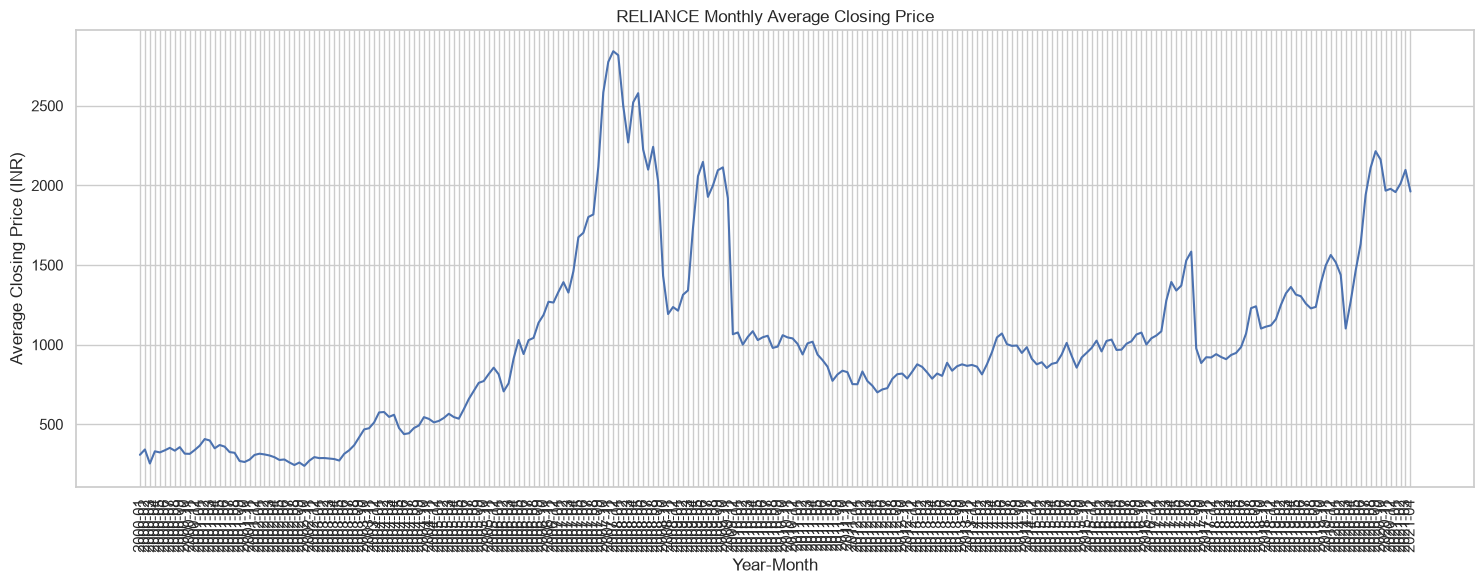

In [19]:
monthly_reliance = (
    reliance_df.groupby("Year_Month")
    .agg(
        Average_Close=("Close", "mean")
    )
    .reset_index()
)

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_reliance["Year_Month"],
    monthly_reliance["Average_Close"]
)

plt.title("RELIANCE Monthly Average Closing Price")
plt.xlabel("Year-Month")
plt.ylabel("Average Closing Price (INR)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### 10.2 Monthly Returns

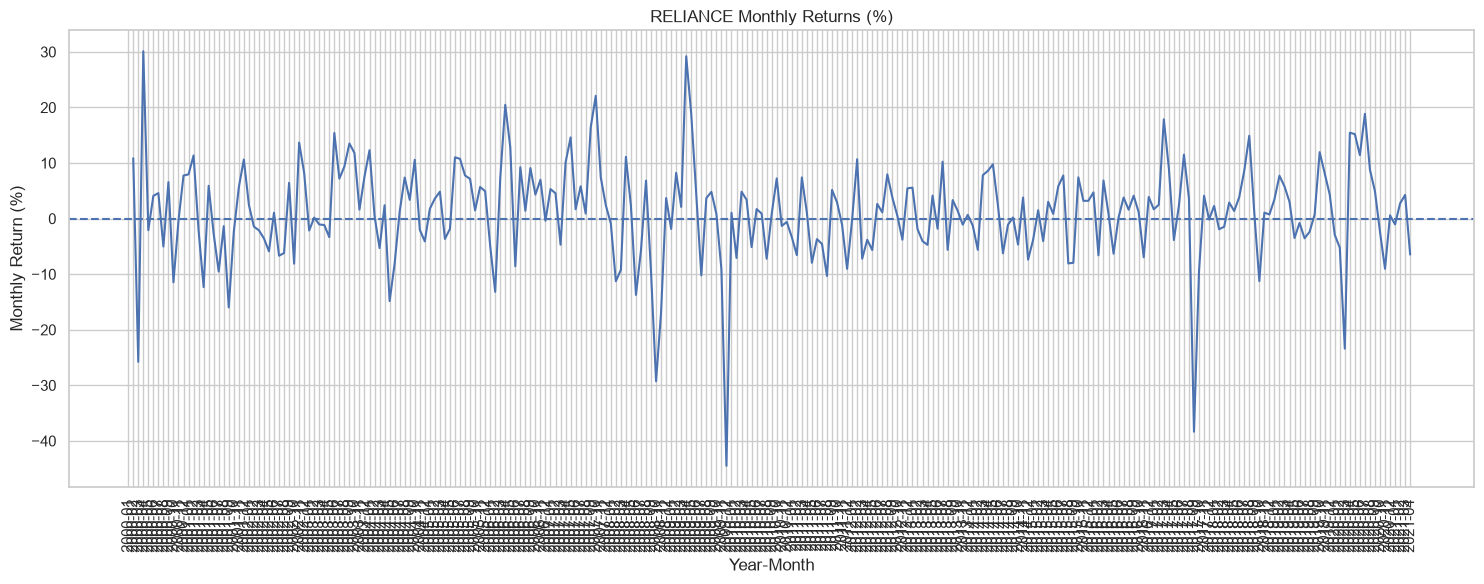

In [20]:
monthly_reliance["Monthly_Return_%"] = (
    monthly_reliance["Average_Close"].pct_change() * 100
)

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_reliance["Year_Month"],
    monthly_reliance["Monthly_Return_%"]
)

plt.axhline(y=0, linestyle="--")

plt.title("RELIANCE Monthly Returns (%)")
plt.xlabel("Year-Month")
plt.ylabel("Monthly Return (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## 11. Daily Return and Volume Distribution

Use histograms to understand the distribution of daily returns and trading volume.

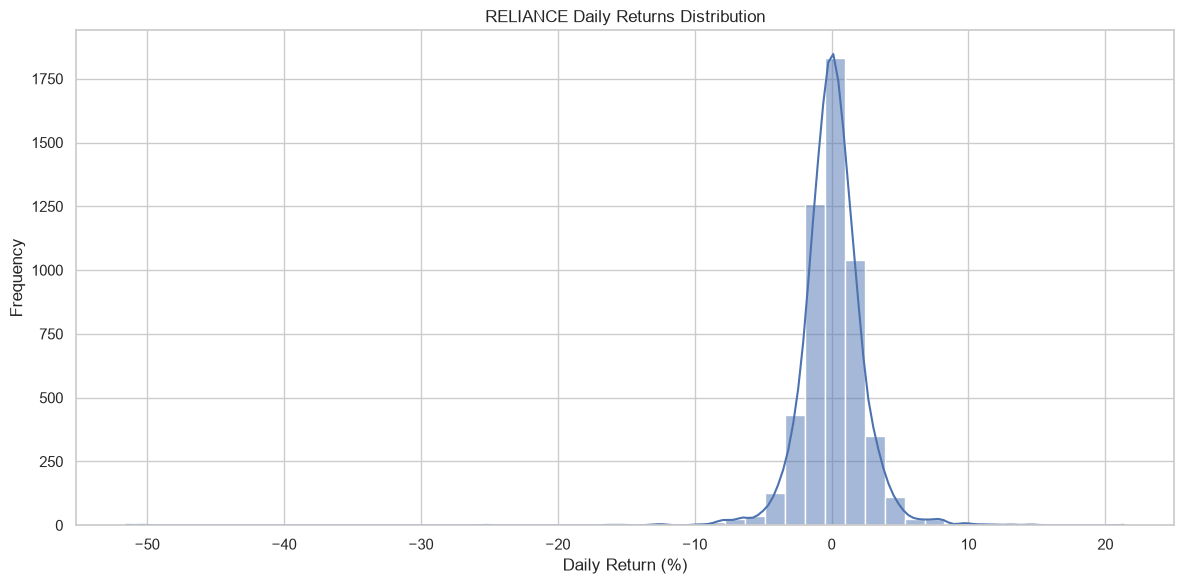

In [22]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=reliance_df,
    x="Daily_Return_%",
    bins=50,
    kde=True
)

plt.title("RELIANCE Daily Returns Distribution")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

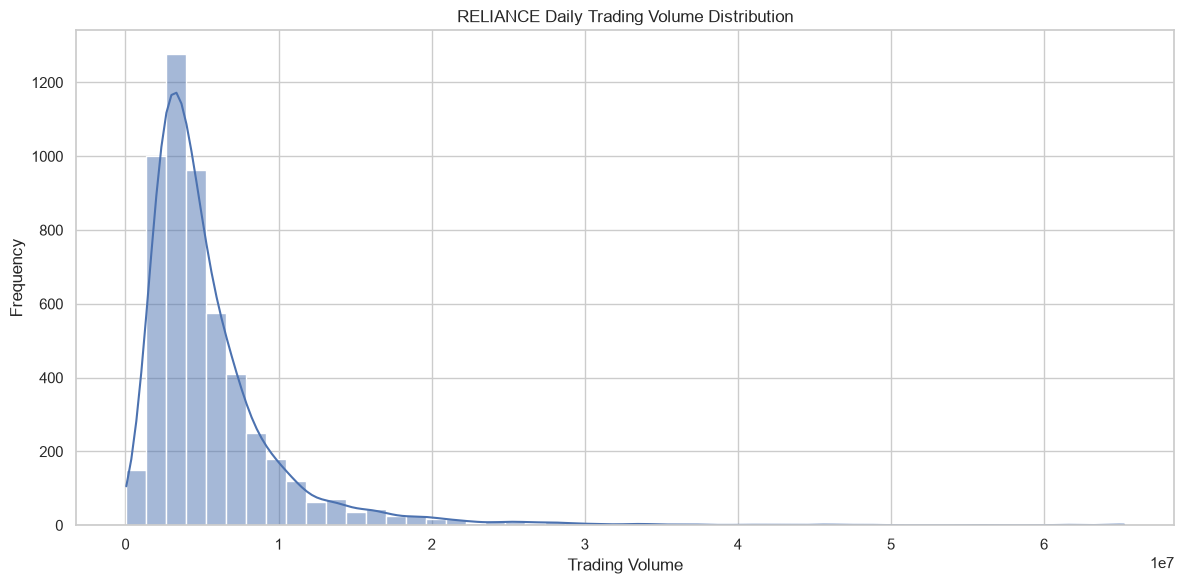

In [23]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=reliance_df,
    x="Volume",
    bins=50,
    kde=True
)

plt.title("RELIANCE Daily Trading Volume Distribution")
plt.xlabel("Trading Volume")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## 12. Relationship Between Daily Returns and Trading Volume

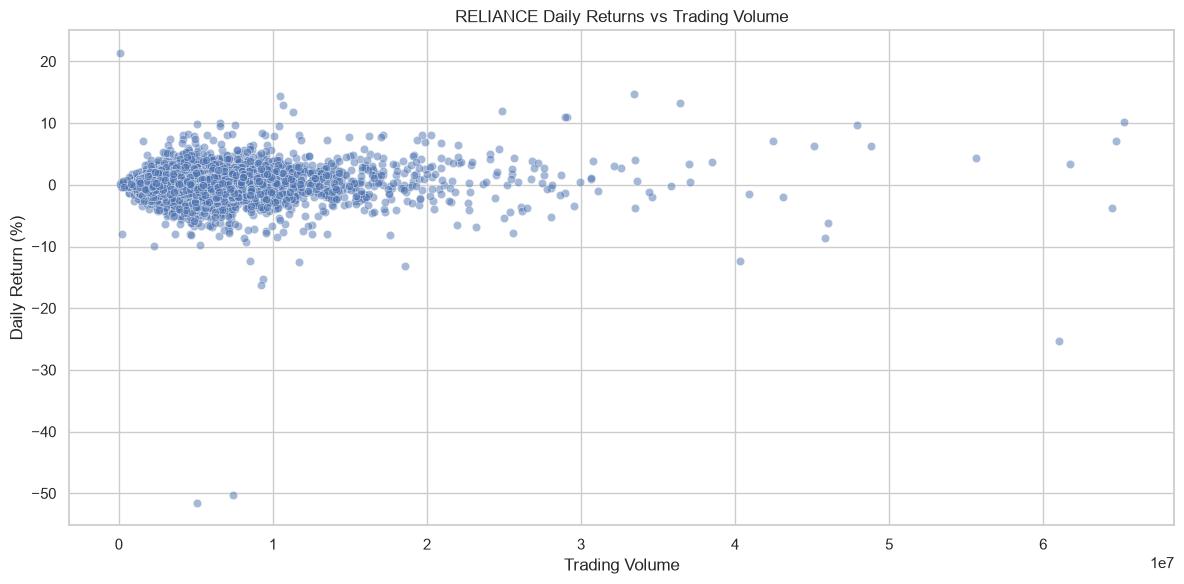

In [24]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=reliance_df,
    x="Volume",
    y="Daily_Return_%",
    alpha=0.5
)

plt.title("RELIANCE Daily Returns vs Trading Volume")
plt.xlabel("Trading Volume")
plt.ylabel("Daily Return (%)")
plt.tight_layout()
plt.show()

## 13. 20-Day Rolling Volatility

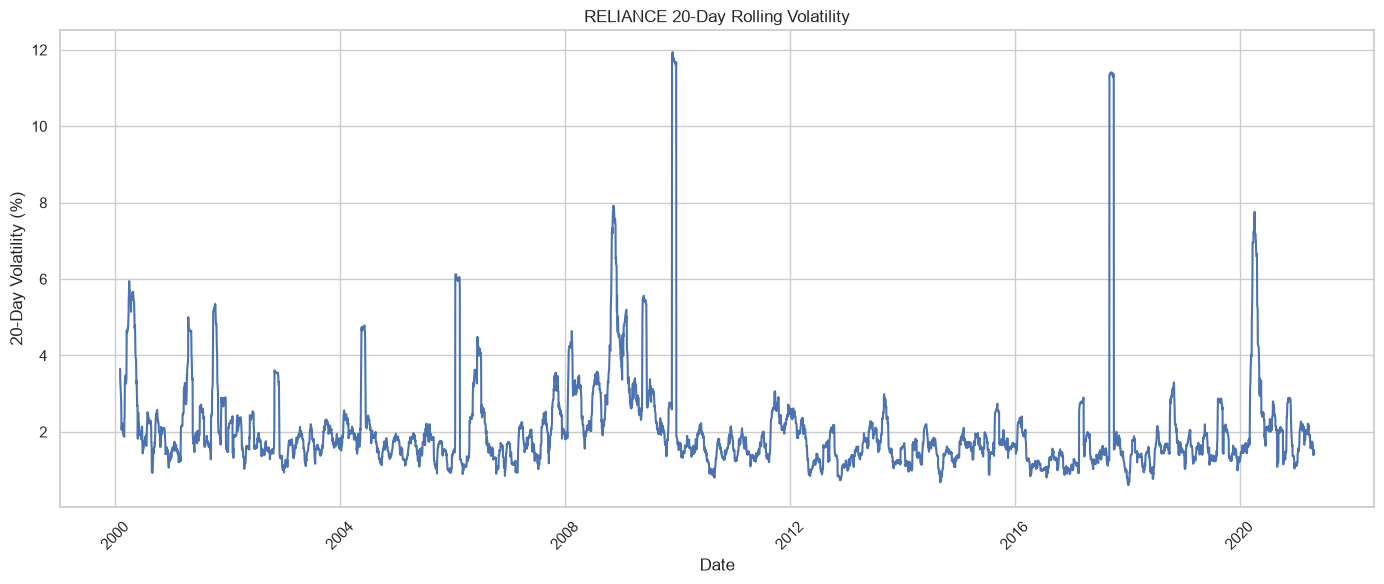

In [25]:
plt.figure(figsize=(14, 6))

plt.plot(
    reliance_df["Date"],
    reliance_df["Volatility_20D_%"]
)

plt.title("RELIANCE 20-Day Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("20-Day Volatility (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

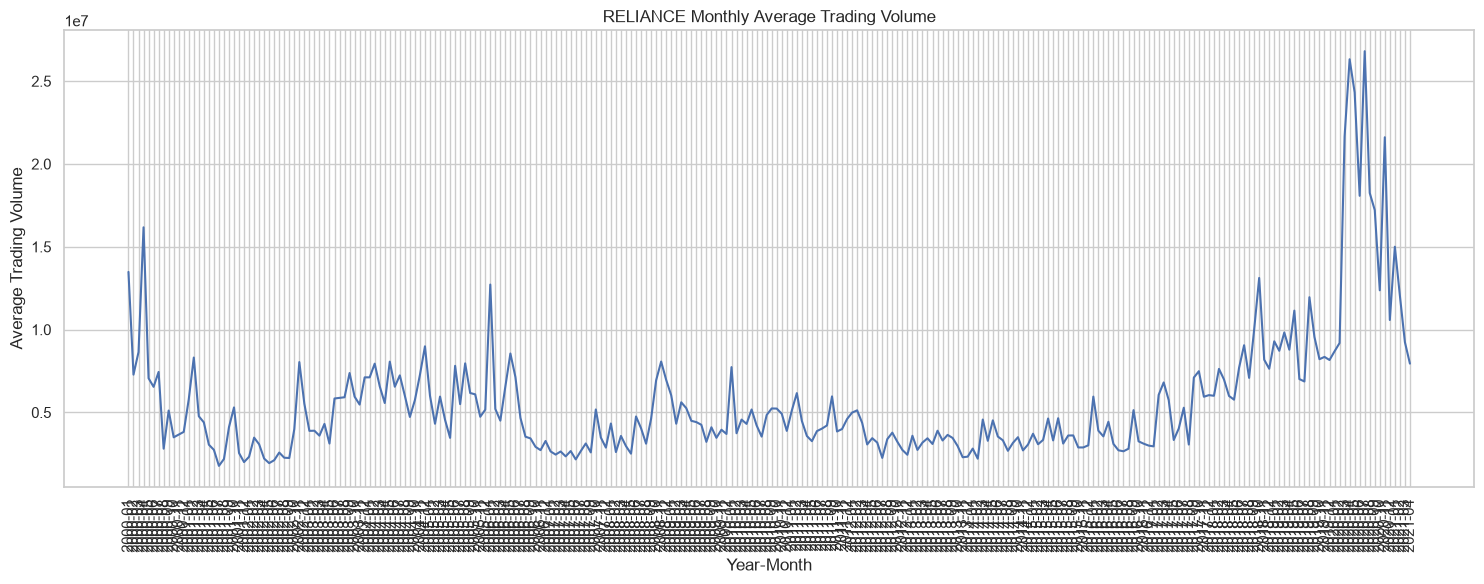

In [26]:
monthly_volume = (
    reliance_df.groupby("Year_Month")
    .agg(Average_Volume=("Volume", "mean"))
    .reset_index()
)

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_volume["Year_Month"],
    monthly_volume["Average_Volume"]
)

plt.title("RELIANCE Monthly Average Trading Volume")
plt.xlabel("Year-Month")
plt.ylabel("Average Trading Volume")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

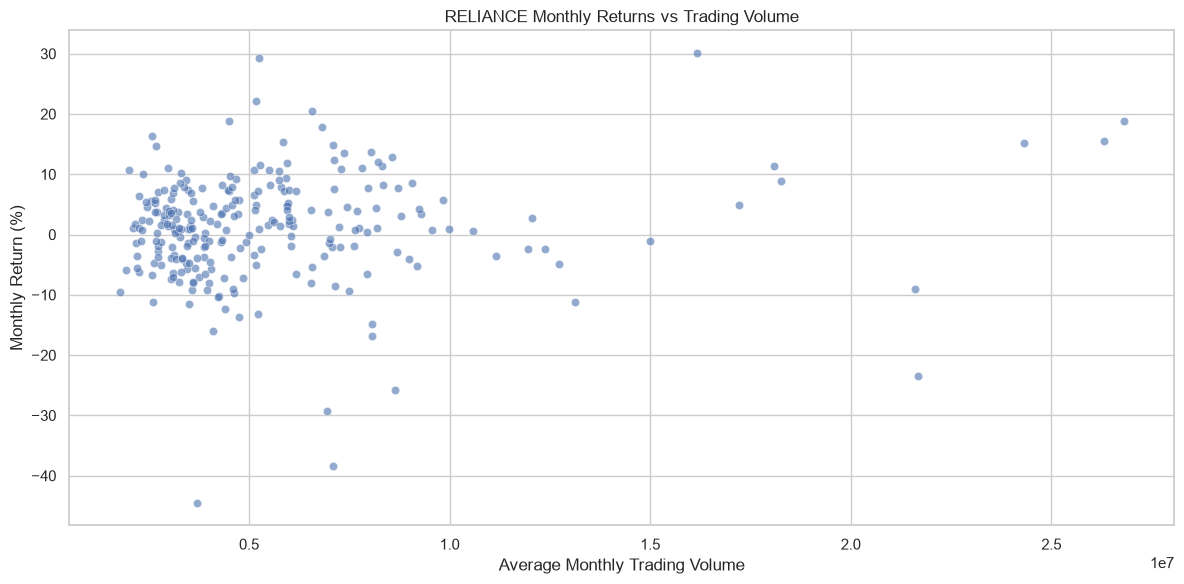

In [27]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=monthly_volume.merge(
        monthly_reliance[["Year_Month", "Monthly_Return_%"]],
        on="Year_Month"
    ),
    x="Average_Volume",
    y="Monthly_Return_%",
    alpha=0.6
)

plt.title("RELIANCE Monthly Returns vs Trading Volume")
plt.xlabel("Average Monthly Trading Volume")
plt.ylabel("Monthly Return (%)")
plt.tight_layout()
plt.show()

## 14. Correlation Analysis

Calculate the correlation between trading volume and daily return, and between trading volume and the absolute value of daily return. Correlation measures association and does not establish causation.

In [28]:
reliance_correlation = reliance_df[
    ["Volume", "Daily_Return_%"]
].corr()

print("RELIANCE Correlation Matrix:")
print(reliance_correlation)

print(
    "\nCorrelation between Volume and Daily Returns:",
    reliance_correlation.loc["Volume", "Daily_Return_%"]
)

RELIANCE Correlation Matrix:
                 Volume  Daily_Return_%
Volume          1.00000         0.05907
Daily_Return_%  0.05907         1.00000

Correlation between Volume and Daily Returns: 0.059070265771939474


In [29]:
reliance_df["Absolute_Return_%"] = reliance_df["Daily_Return_%"].abs()

absolute_return_corr = reliance_df[
    ["Volume", "Absolute_Return_%"]
].corr()

print("Volume vs Absolute Daily Return Correlation:")
print(absolute_return_corr)

print(
    "\nCorrelation:",
    absolute_return_corr.loc["Volume", "Absolute_Return_%"]
)

Volume vs Absolute Daily Return Correlation:
                     Volume  Absolute_Return_%
Volume             1.000000           0.295611
Absolute_Return_%  0.295611           1.000000

Correlation: 0.29561073471178756


### 14.1 Correlation Heatmap

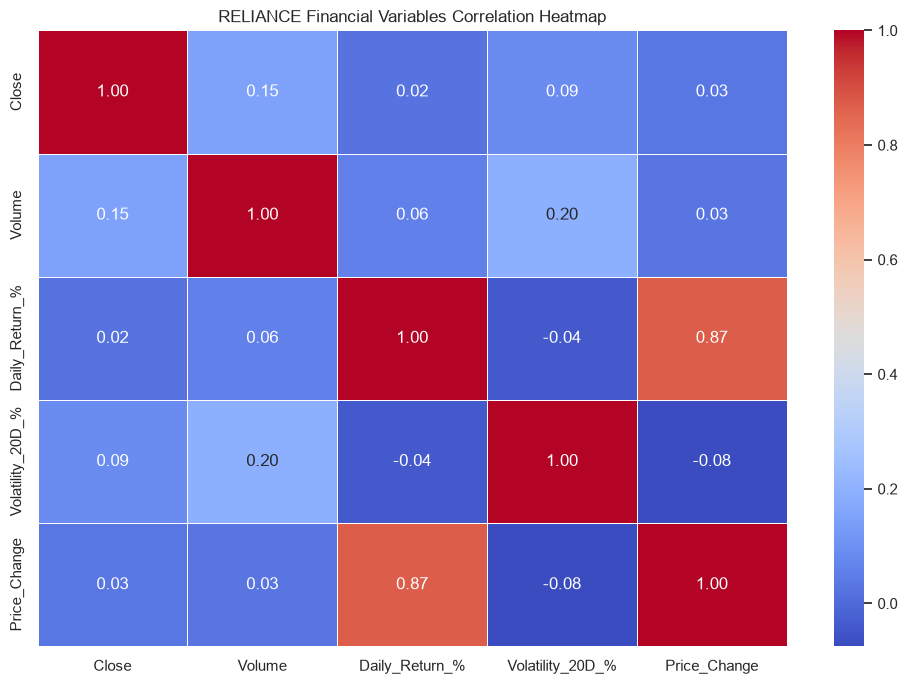

In [30]:
correlation_data = reliance_df[
    ["Close", "Volume", "Daily_Return_%",
     "Volatility_20D_%", "Price_Change"]
].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_data,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("RELIANCE Financial Variables Correlation Heatmap")
plt.tight_layout()
plt.show()

## 15. Prepare RELIANCE Data for Forecasting

Create a time series containing the date and closing price. Sort by date and set the date as the index.

In [31]:
reliance_forecast = reliance_df[
    ["Date", "Close"]
].copy()

reliance_forecast = reliance_forecast.sort_values("Date")

reliance_forecast = reliance_forecast.set_index("Date")

print("Forecasting Dataset:")
print(reliance_forecast.head())

print("\nDataset Shape:", reliance_forecast.shape)

print("\nMissing Values:")
print(reliance_forecast.isnull().sum())

Forecasting Dataset:
             Close
Date              
2000-01-03  251.70
2000-01-04  271.85
2000-01-05  282.50
2000-01-06  294.35
2000-01-07  314.55

Dataset Shape: (5306, 1)

Missing Values:
Close    0
dtype: int64


## 16. Train-Test Split

Use a chronological 80/20 split. The earlier 80% is used for training and the latest 20% is used for testing. Do not shuffle time-series observations.

In [32]:
split_index = int(len(reliance_forecast) * 0.80)

train_data = reliance_forecast.iloc[:split_index]
test_data = reliance_forecast.iloc[split_index:]

print("Training Data Shape:", train_data.shape)
print("Testing Data Shape:", test_data.shape)

print("\nTraining Period:")
print(train_data.index.min(), "to", train_data.index.max())

print("\nTesting Period:")
print(test_data.index.min(), "to", test_data.index.max())

Training Data Shape: (4244, 1)
Testing Data Shape: (1062, 1)

Training Period:
2000-01-03 00:00:00 to 2017-01-12 00:00:00

Testing Period:
2017-01-13 00:00:00 to 2021-04-30 00:00:00


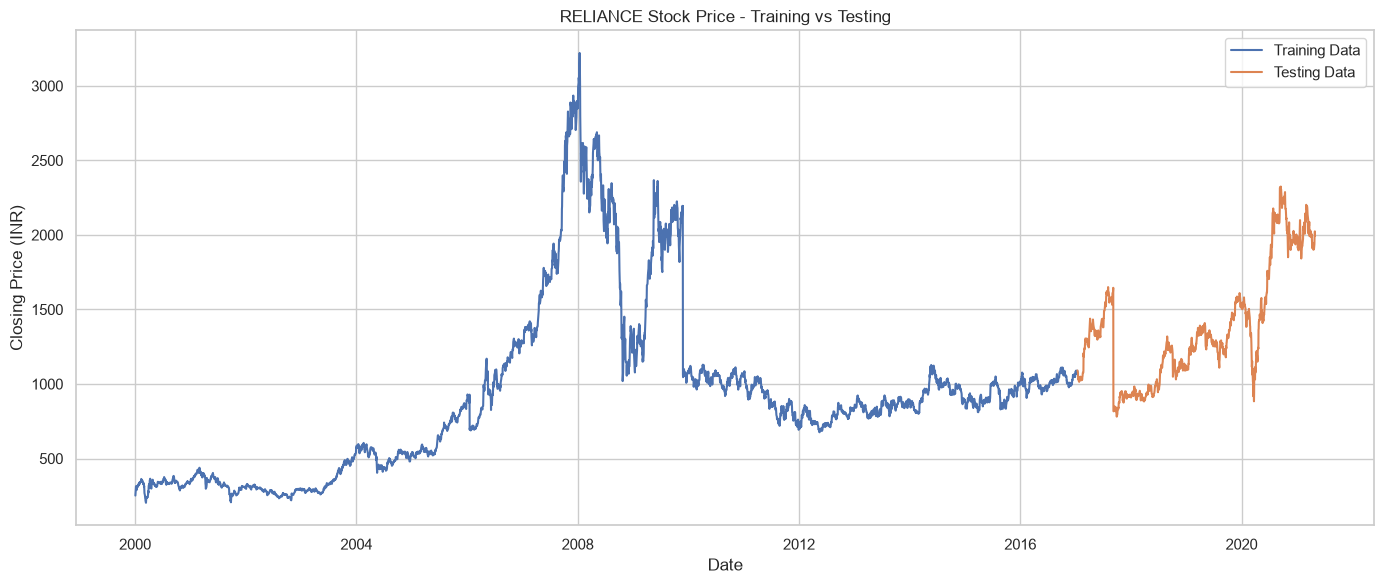

In [33]:
plt.figure(figsize=(14, 6))

plt.plot(
    train_data.index,
    train_data["Close"],
    label="Training Data"
)

plt.plot(
    test_data.index,
    test_data["Close"],
    label="Testing Data"
)

plt.title("RELIANCE Stock Price - Training vs Testing")
plt.xlabel("Date")
plt.ylabel("Closing Price (INR)")
plt.legend()
plt.tight_layout()
plt.show()

## 17. Build the ARIMA Model

Fit an ARIMA(5, 1, 0) model using the training closing prices. An integer index is used for the training series to avoid the unsupported-date-index forecast warning. Forecast the same number of observations as the test dataset.

In [34]:
arima_model = ARIMA(
    train_data["Close"],
    order=(5, 1, 0)
)

arima_result = arima_model.fit()

print(arima_result.summary())


                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                 4244
Model:                 ARIMA(5, 1, 0)   Log Likelihood              -20727.372
Date:                Fri, 30 Oct 2026   AIC                          41466.744
Time:                        19:06:05   BIC                          41504.862
Sample:                             0   HQIC                         41480.215
                               - 4244                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0358      0.008      4.609      0.000       0.021       0.051
ar.L2         -0.0041      0.009     -0.432      0.666      -0.023       0.014
ar.L3         -0.0815      0.009     -9.451      0.0

In [36]:
# Create a new training series with a supported index
train_series = pd.Series(
    train_data["Close"].values,
    index=range(len(train_data))
)

# Fit ARIMA model again
arima_model = ARIMA(
    train_series,
    order=(5, 1, 0)
)

arima_result = arima_model.fit()

# Generate forecast
forecast_values = arima_result.forecast(
    steps=len(test_data)
)

# Assign test dates
forecast_values.index = test_data.index

print("First 10 Forecast Predictions:")
print(forecast_values.head(10))

First 10 Forecast Predictions:
Date
2017-01-13    1082.251081
2017-01-16    1082.077509
2017-01-17    1081.900238
2017-01-18    1082.216066
2017-01-19    1082.386481
2017-01-20    1082.454377
2017-01-23    1082.442596
2017-01-24    1082.426495
2017-01-25    1082.402459
2017-01-27    1082.393605
Name: predicted_mean, dtype: float64


## 18. Model Evaluation

Calculate Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE) and Mean Absolute Percentage Error (MAPE). These metrics evaluate predictions over the historical test period.

In [37]:
comparison_df = pd.DataFrame({
    "Actual_Close": test_data["Close"],
    "Predicted_Close": forecast_values
})

print("Actual vs Predicted Prices:")
print(comparison_df.head(10))

Actual vs Predicted Prices:
            Actual_Close  Predicted_Close
Date                                     
2017-01-13       1090.40      1082.251081
2017-01-16       1076.25      1082.077509
2017-01-17       1041.25      1081.900238
2017-01-18       1032.55      1082.216066
2017-01-19       1033.70      1082.386481
2017-01-20       1025.80      1082.454377
2017-01-23       1015.90      1082.442596
2017-01-24       1027.30      1082.426495
2017-01-25       1017.30      1082.402459
2017-01-27       1025.10      1082.393605


In [38]:
mae = mean_absolute_error(
    comparison_df["Actual_Close"],
    comparison_df["Predicted_Close"]
)

mse = mean_squared_error(
    comparison_df["Actual_Close"],
    comparison_df["Predicted_Close"]
)

rmse = np.sqrt(mse)

print("ARIMA Model Evaluation")
print("----------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

ARIMA Model Evaluation
----------------------
MAE: 365.95134591948016
MSE: 239320.8431016055
RMSE: 489.20429587403004


## 19. Actual vs Predicted Closing Price

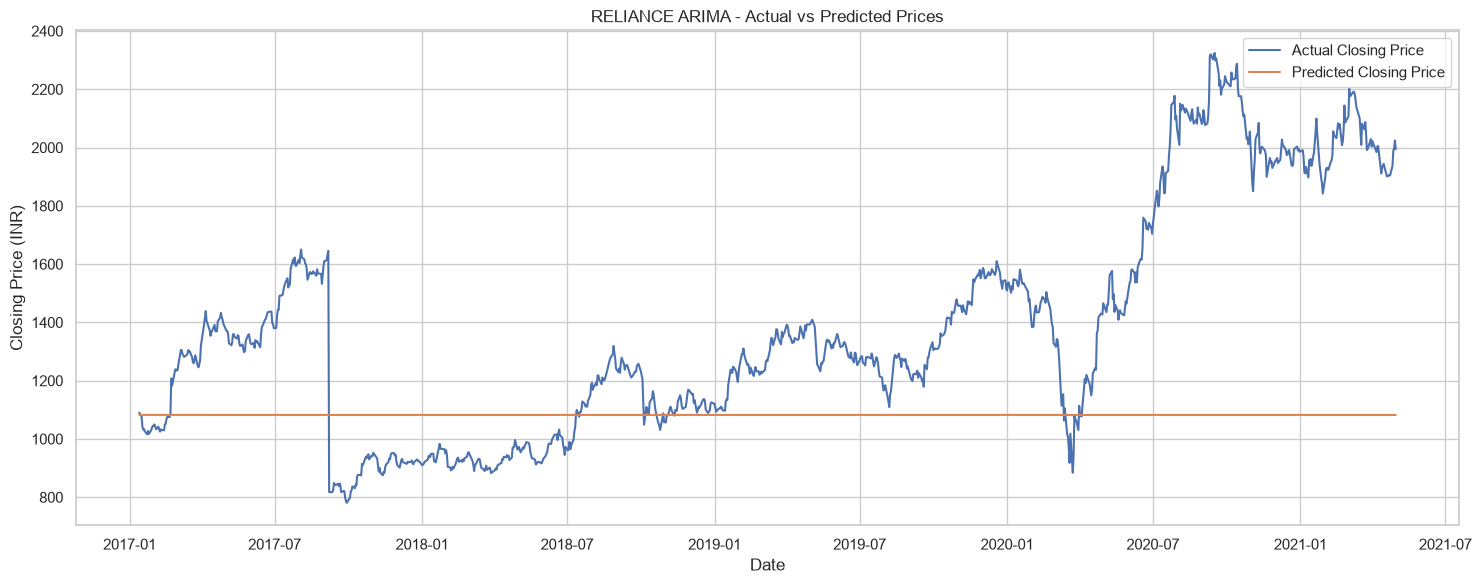

In [39]:
plt.figure(figsize=(15, 6))

plt.plot(
    comparison_df.index,
    comparison_df["Actual_Close"],
    label="Actual Closing Price"
)

plt.plot(
    comparison_df.index,
    comparison_df["Predicted_Close"],
    label="Predicted Closing Price"
)

plt.title("RELIANCE ARIMA - Actual vs Predicted Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price (INR)")
plt.legend()
plt.tight_layout()
plt.show()

In [40]:
mape = np.mean(
    np.abs(
        (comparison_df["Actual_Close"] -
         comparison_df["Predicted_Close"])
        / comparison_df["Actual_Close"]
    )
) * 100

print("Mean Absolute Percentage Error (MAPE):", mape, "%")

Mean Absolute Percentage Error (MAPE): 23.03496229494518 %


## 20. Save Analysis Results

Export the cleaned data, stock summary, monthly analysis, correlation results and ARIMA predictions as CSV files.

In [41]:
comparison_df.to_csv(
    "RELIANCE_ARIMA_Forecast_Results.csv"
)

print("Forecast results saved successfully!")

Forecast results saved successfully!


In [42]:
financial_df.to_csv(
    "NIFTY50_Cleaned_Financial_Data.csv",
    index=False
)

print("Cleaned financial dataset saved successfully!")

Cleaned financial dataset saved successfully!


In [43]:
stock_summary.to_csv(
    "NIFTY50_Stock_Wise_Summary.csv",
    index=False
)

print("Stock-wise summary saved successfully!")

Stock-wise summary saved successfully!


In [44]:
monthly_reliance.to_csv(
    "RELIANCE_Monthly_Analysis.csv",
    index=False
)

print("Monthly RELIANCE analysis saved successfully!")

Monthly RELIANCE analysis saved successfully!


In [45]:
reliance_correlation.to_csv(
    "RELIANCE_Correlation_Analysis.csv"
)

print("Correlation analysis saved successfully!")

Correlation analysis saved successfully!


## 21. PostgreSQL Database Connection (Optional)

Create a PostgreSQL database named `nifty50_analysis` before running this section. Install the required packages if they are not already available:

`pip install sqlalchemy psycopg2-binary`

Enter your PostgreSQL password securely when prompted. Do not hard-code passwords or upload them to GitHub.

In [46]:
!pip install sqlalchemy psycopg2-binary


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [47]:
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

connection_url = URL.create(
    drivername="postgresql+psycopg2",
    username="postgres",
    password="210750",
    host="localhost",
    port=5432,
    database="nifty50_analysis"
)

engine = create_engine(connection_url)

with engine.connect() as connection:
    result = connection.execute(text("SELECT current_database();"))
    print("Connected to database:", result.scalar())

Connected to database: nifty50_analysis


In [49]:
financial_df.to_sql(
    "nifty50_cleaned",
    engine,
    if_exists="replace",
    index=False,
    chunksize=10000
)

print("Data uploaded successfully!")

Data uploaded successfully!


In [50]:
with engine.connect() as connection:
    result = connection.execute(
        text("SELECT COUNT(*) FROM nifty50_cleaned;")
    )
    print("Total uploaded rows:", result.scalar())

Total uploaded rows: 235192


In [51]:
stock_summary.to_sql(
    "stock_summary",
    engine,
    if_exists="replace",
    index=False
)

print("Stock summary uploaded successfully!")

Stock summary uploaded successfully!


In [52]:
monthly_reliance.to_sql(
    "reliance_monthly",
    engine,
    if_exists="replace",
    index=False
)

print("RELIANCE monthly analysis uploaded successfully!")

RELIANCE monthly analysis uploaded successfully!


In [53]:
monthly_volume.to_sql(
    "reliance_monthly_volume",
    engine,
    if_exists="replace",
    index=False
)

print("RELIANCE monthly volume uploaded successfully!")

RELIANCE monthly volume uploaded successfully!


In [54]:
reliance_correlation.reset_index().to_sql(
    "reliance_correlation",
    engine,
    if_exists="replace",
    index=False
)

print("RELIANCE correlation analysis uploaded successfully!")

RELIANCE correlation analysis uploaded successfully!


In [55]:
comparison_df.reset_index().to_sql(
    "reliance_arima_forecast",
    engine,
    if_exists="replace",
    index=False
)

print("ARIMA forecasting results uploaded successfully!")

ARIMA forecasting results uploaded successfully!
